<a href="https://colab.research.google.com/github/Seamuscs/Brent-and-WTI-spread-analysis/blob/main/Part_II_Statistical_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Part II - Statistical Analysis**
In this part I want to do more advanced statistical analysis, for this I will remove one of the limitations from the last part. I will work with futures instead as this is what electronic trades are made on. Sadly, my university will not let me use their Bloomberg terminal but I will use a free alternative and only starts in 2007, though our objective is not to be profitable but to analyse and learn.

#  2.1 - Futures

In [3]:
import yfinance as yf
import matplotlib.pyplot as plt
import numpy as np
from google.colab import drive
import pandas as pd
drive.mount('/content/drive')
df = pd.read_parquet('/content/drive/MyDrive/Brent_and_WTI_spread_analysis_project/adjusted_spot_data.parquet')


Mounted at /content/drive


In [4]:
fut = yf.download(["BZ=F", "CL=F"], start="2007-01-01")["Close"]
fut.columns = ["brent_fut", "wti_fut"]
fut.dropna(inplace=True)
fut

/tmp/ipykernel_1698/829486332.py:1: FutureWarning: YF.download() has changed argument auto_adjust default to True
  fut = yf.download(["BZ=F", "CL=F"], start="2007-01-01")["Close"]
[*********************100%***********************]  2 of 2 completed


,brent_fut,wti_fut
Date,,
2007-07-30,75.739998,76.830002
2007-07-31,77.050003,78.209999
2007-08-01,75.349998,76.529999
2007-08-02,75.760002,76.860001
2007-08-03,74.750000,75.480003
...,...,...
2026-10-27,113.879997,99.900002
2026-10-28,115.320000,102.779999
2026-10-29,114.879997,102.000000


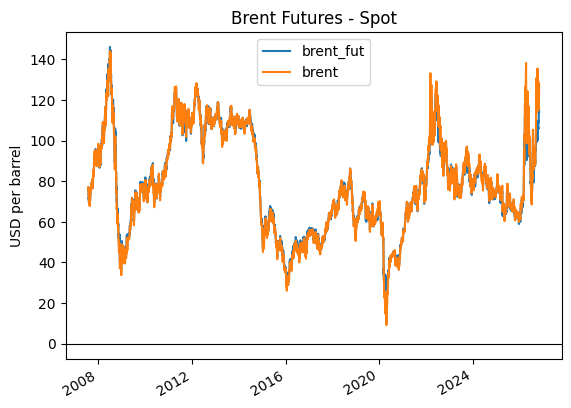

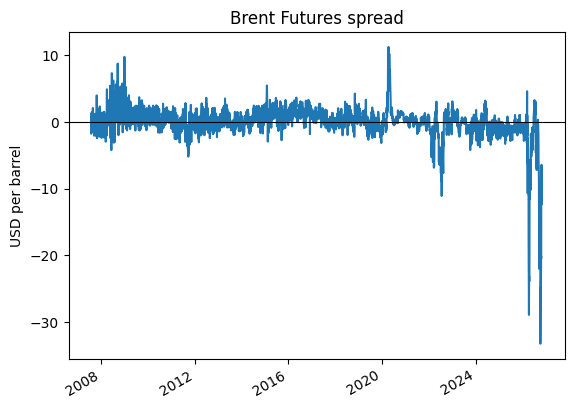

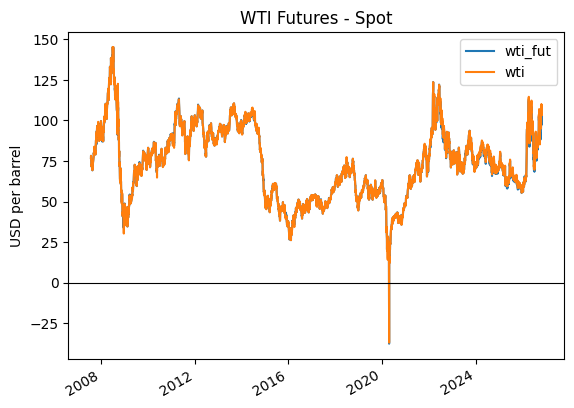

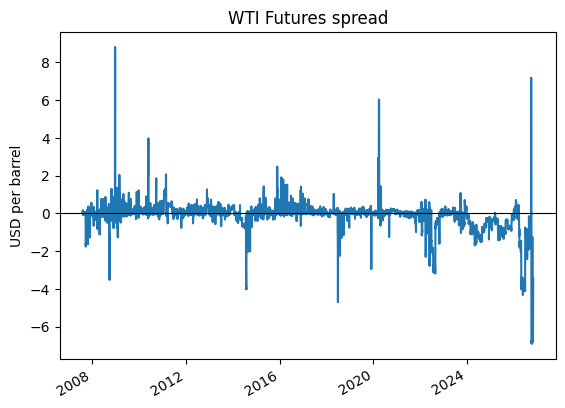

In [5]:
comp_1  = pd.concat([fut["brent_fut"], df["brent"]], axis=1, join="inner")
comp_1.columns = ["brent_fut", "brent"]
ex = comp_1.plot()
ex.set_title("Brent Futures - Spot")
ex.set_ylabel("USD per barrel")
ex.axhline(0, color="black", linewidth=0.8)
plt.show()

comp_1["fut_spread"] = comp_1["brent_fut"] - comp_1["brent"]
fx = comp_1["fut_spread"].plot()
fx.set_title("Brent Futures spread")
fx.set_ylabel("USD per barrel")
fx.axhline(0, color="black", linewidth=0.8)
plt.show()

comp_2  = pd.concat([fut["wti_fut"], df["wti"]], axis=1, join="inner")
comp_2.columns = ["wti_fut", "wti"]
gx = comp_2.plot()
gx.set_title("WTI Futures - Spot")
gx.set_ylabel("USD per barrel")
gx.axhline(0, color="black", linewidth=0.8)
plt.show()

comp_2["fut_spread"] = comp_2["wti_fut"] - comp_2["wti"]
hx = comp_2["fut_spread"].plot()
hx.set_title("WTI Futures spread")
hx.set_ylabel("USD per barrel")
hx.axhline(0, color="black", linewidth=0.8)
plt.show()

As you can see by the speads of each of the benchmarks futures, they can change quite drastically. I hope from Part I you can see that the sharp deviations in spread line up with key world events. This is because of tumultous markets, by definition futures and spot prices are quite different and this difference is emphasised when prices jump around

# 2.2 - Testing for mean reversion

As aforementioned in the last part, means change after major economic events but the question this time is, do prices eventually fall back to the mean save for some 'noise'? There is no yes or no answer here other than to find out and test for it. To test for mean reversion, I shall first describe how and what we use to do it.

There are multiple ways of testing for mean-reversion. Using a diverse range of test also strengthens the reliability of any model or conclusion we produce. I will detail a more mathematical derivation in the appendix of the repository. The first one we shall use is the ADF (Augmented Dickey-Fuller) Test.

We let $P_t$ be the time series of our futures prices of our Brent - WTI spread with t indexed in time by our dates. The ADF Test will take in our data and return us with a test statistic. The null and alternative hypthothesis are such:

*   $H_0$ Null hypothesis: $P_t$ has a unit root meaning it is non stationary and so not mean-reverting
*   $H_1$ Alternative hypothesis: $P_t$ has no unit root meaning it is stationary and so mean-reverts





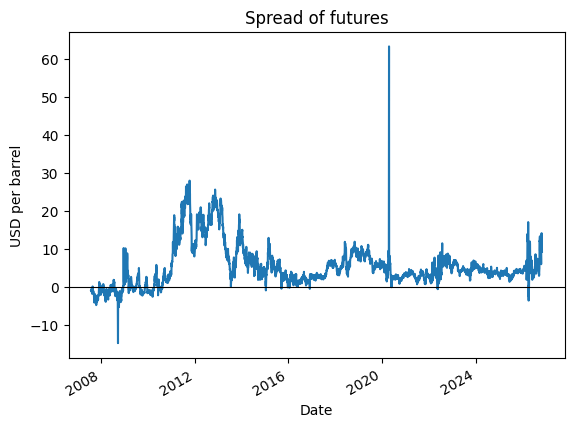

In [6]:
futures = pd.concat([fut["brent_fut"], fut["wti_fut"]], axis=1, join="inner")
futures["spread_fut"] = futures["brent_fut"] - futures["wti_fut"]

plot_1 = futures['spread_fut'].plot()
plot_1.set_title("Spread of futures")
plot_1.set_ylabel("USD per barrel")
plot_1.axhline(0, color="black", linewidth=0.8)
plt.show()

I quickly made a data frame for our futures prices for ease of use and gave us a plot. It will be important to consider this as a visual reference when thinking about the limitations of some of our tests.

In [7]:
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

adfuller(futures["spread_fut"])

/tmp/ipykernel_1698/2103045991.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adfuller(futures["spread_fut"])


(-3.5348429463608304,
 0.007136066632355152,
 23,
 4770,
 {'1%': np.float64(-3.4317216609158665),
  '5%': np.float64(-2.8621461193691413),
  '10%': np.float64(-2.5670926391800606)},
 np.float64(15685.272415362431))

The ADF test concludes that $P_t$ mean reverts with a lag of 23 and is a critical value for 1%, 5% and 10% significance levels. This alone is only one test and the ADF test has its limitations. Which is why next we will use KPSS test.

The KPSS is almost always used in conjuction with the ADF test as their hypotheses are reversed essentially. The null and alternate hypothesis for the KPSS test are such:

*   $H_0$ Null hypothesis: $P_t$ is stationary
*   $H_1$ Alternate hypothesis: $P_t$ is not stationary

so we are looking to maintain the null hypothesis.

In [8]:
from statsmodels.tsa.stattools import kpss
kpss(futures["spread_fut"])

/tmp/ipykernel_1698/3758855121.py:2: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  kpss(futures["spread_fut"])


(np.float64(0.7184228982007589),
 np.float64(0.011870645618112827),
 41,
 {'10%': 0.347, '5%': 0.463, '2.5%': 0.574, '1%': 0.739})

We can see that our test statistic for the KPSS test is not significant and so we maintain the null hypothesis that $P_t$ is stationary. We have now used two tests to show that $P_t$ is mean-reverting with signigicance levels of less than $1\%$. We can safely assume that $P_t$ mean-reverts.

# 2.3 Fitting a model

What we have been building to so far is this idea of mean-reversion. This is one of the assumptions required to fit the Ornstein-Uhlenbeck process. It is a stochastic process $x_t$ defined by the follow stochastic differential equation:





\begin{align*}
dX_t = - \theta (X_t-\mu)dt + \sigma dW_t
\end{align*}






where we have:

*   $\theta$ is the parameter for the rate of decay of the process
*   $\mu$ is the parameter for the mean that the process reverts to
*   $\sigma$ is the degree of volatility
*   $W_t$ is the Wiener process

All that is required to know is that a small increase in time leads to a small change toward the mean $\mu$ a some rate $\theta$ with a random noise term. For more technical details, again see the appendix in the repository.

Though it makes no sense no make use of a continous model for discrete data so we will make a discrete version:

\begin{align*}
 X_{t + \delta t} - X_{t} = -\theta(X_t - \mu)\delta t +\sigma ( W_{t+\delta t} - W_{t})
\end{align*}

By definition of the wiener process, $W_{t+\delta t} - W_{t} \sim  \mathcal{N}(0,\delta t)$. We can therefore also just sample from $\mathcal{N}(0,1)$, the standard normal and multiply by some $\sqrt \delta t$. Define $Z_t \sim \mathcal{N}(0,1)$ and we write our descretised OU process as:

\begin{align*}
 X_{t + \delta t} = X_t -\theta(X_t - \mu)\delta t +\sigma\sqrt\delta t Z_t
\end{align*}

Now this is something we can code, though our $\delta t$ will always be greater than or equal to 1 as there is no data for multiple prices per day and sometimes there are no prices on a day. We can code a recursive definition then of the OU process:

\begin{align*}
 X_{n+1} = (1-\theta)X_n + \mu \theta +\sigma Z_t
\end{align*}

In [14]:
futures.describe()


,brent_fut,wti_fut,spread_fut
count,4794.000000,4794.000000,4794.000000
mean,78.626468,73.353087,5.273381
std,23.662480,21.784652,5.459495
min,19.330000,-37.630001,-14.879997
25%,61.874999,56.525001,2.270000
50%,76.169998,72.750000,3.940002
75%,98.970001,90.530001,6.750000
max,146.080002,145.289993,63.200001


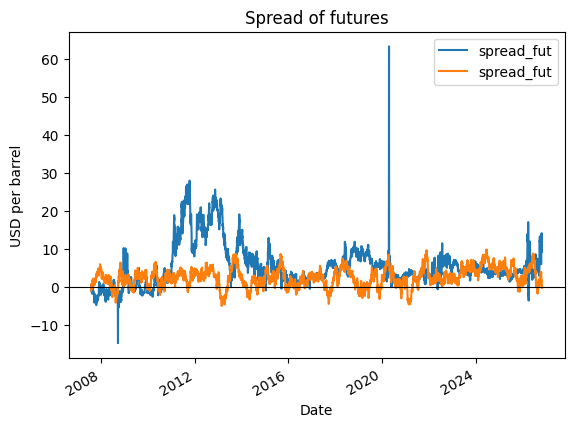

In [27]:
def simulate_OU(x0, n, theta, mu, sigma, rng=None):
    rng = np.random.default_rng() if rng is None else rng
    A = [x0]
    for t in range(1, n):
        A.append((1 - theta) * A[-1] + theta * mu + sigma * rng.standard_normal())
    return np.array(A)

x0 = futures["spread_fut"].iloc[0]
path = simulate_OU(x0, len(futures), theta=0.02, mu=2, sigma=0.5)

path_df = pd.DataFrame(path, columns=["spread_fut"], index=futures.index)
OU_model = pd.concat([futures["spread_fut"] , path_df], axis =1)
plot_2 = OU_model.plot()
plot_2.set_title("Spread of futures")
plot_2.set_ylabel("USD per barrel")
plot_2.axhline(0, color="black", linewidth=0.8)
plt.show()


Thats a pretty pathetic showing so far but with some maths we can minimise how close it is from the curve.

In [34]:
import numpy as np
from scipy.optimize import minimize

x = futures["spread_fut"].dropna().to_numpy()
x_now, x_next = x[:-1], x[1:]

def neg_log_lik(params):
    theta, mu, sigma = params
    b = np.exp(-theta)
    v = sigma**2 * (1 - b**2) / (2 * theta)   # variance of the one-step shock
    resid = x_next - (mu + (x_now - mu) * b)  # real tomorrow minus predicted
    n = len(resid)
    return 0.5 * n * np.log(2 * np.pi * v) + np.sum(resid**2) / (2 * v)

res = minimize(neg_log_lik, x0=[0.02, x.mean(), x.std() * 0.2],
               method="L-BFGS-B",
               bounds=[(1e-6, None), (None, None), (1e-6, None)])
print(res.x, res.success)

[0.03163891 5.27351062 1.37128807] True


Much better lets plot this then

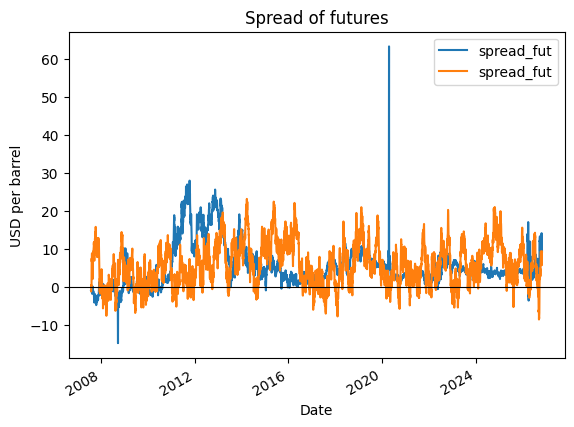

In [37]:
x0 = futures["spread_fut"].iloc[0]
path_1 = simulate_OU(x0, len(futures), theta= 0.03163891, mu= 5.27351062, sigma=1.37128807)

path_1_df = pd.DataFrame(path_1, columns=["spread_fut"], index=futures.index)
OU_model2 = pd.concat([futures["spread_fut"] , path_1_df], axis =1)
plot_2 = OU_model2.plot()
plot_2.set_title("Spread of futures")
plot_2.set_ylabel("USD per barrel")
plot_2.axhline(0, color="black", linewidth=0.8)
plt.show()

Still ongoing...